In [1]:
import pandas as pd

df= pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [6]:
df["isBestSeller"] = df["isBestSeller"].astype(int)

In [7]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,0,1
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
category_counts = df["category"].value_counts()

In [9]:
valid_categories = category_counts[category_counts >= 100].index
df_filtered = df[df["category"].isin(valid_categories)]

In [10]:
crosstab_f = pd.crosstab(df_filtered["category"], df_filtered["isBestSeller"])

crosstab_f["best_seller_proportion"] = (
    crosstab_f[1] / crosstab_f.sum(axis=1)
)

best_seller_ranked_f = crosstab_f.sort_values(
    by="best_seller_proportion",
    ascending=False
)

best_seller_ranked_f

isBestSeller,0,1,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
CPUs,249,0,0.000000
"CD, Disc & Tape Players",8798,0,0.000000
Graphics Cards,249,0,0.000000


In [11]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(
    df_filtered["category"],
    df_filtered["isBestSeller"]
)

In [12]:
chi2, p_value, dof, expected = chi2_contingency(contingency)

chi2, p_value

(np.float64(36540.102113591915), np.float64(0.0))

Decision 

p < 0.05 → Reject independence

p ≥ 0.05 → No statistically significant relationship

In [13]:
import numpy as np

n = contingency.to_numpy().sum()
min_dim = min(contingency.shape) - 1

cramers_v = np.sqrt((chi2 / n) / min_dim)
cramers_v

np.float64(0.12228412679690605)

Interpretation guideline

0.00–0.10 → very weak

0.10–0.30 → weak

0.30–0.50 → moderate

> 0.50 → strong

In [14]:
proportion_table = contingency.div(
    contingency.sum(axis=1),
    axis=0
)

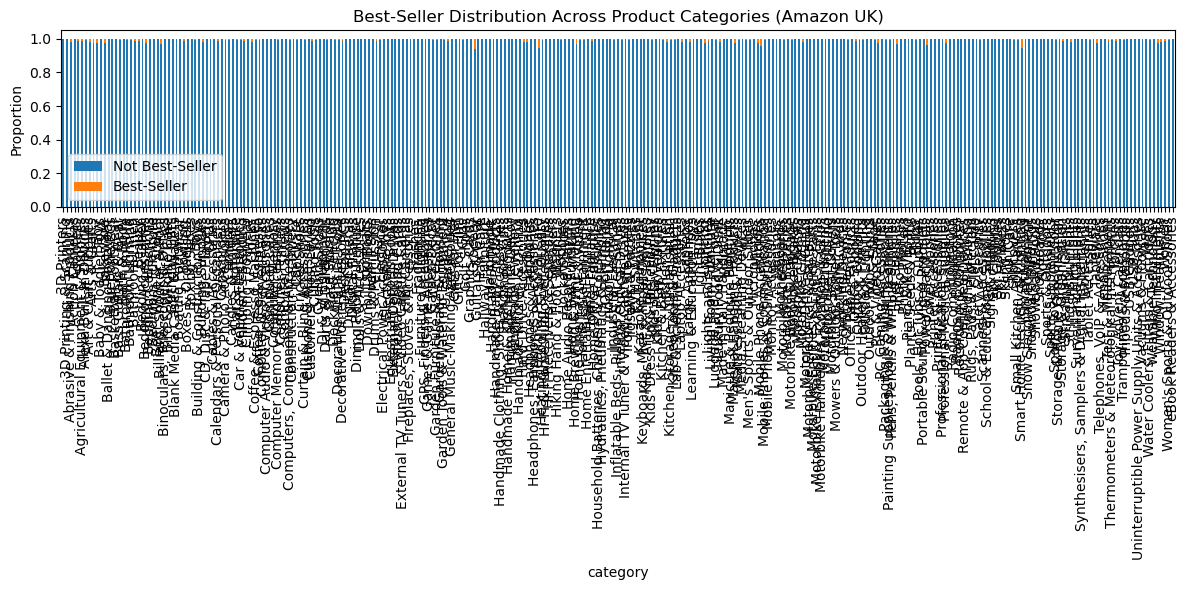

In [15]:
import matplotlib.pyplot as plt

proportion_table.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.ylabel("Proportion")
plt.title("Best-Seller Distribution Across Product Categories (Amazon UK)")
plt.legend(["Not Best-Seller", "Best-Seller"])
plt.tight_layout()
plt.show()

A crosstabulation analysis of the Amazon UK dataset revealed substantial variation in best-seller prevalence across product categories. After excluding low-volume categories, several categories exhibited notably higher proportions of best-selling products.

A Chi-square test of independence indicated that best-seller status is not independent of product category (p < 0.05). However, the computed Cramér’s V suggested a weak association, implying that while category influences best-seller likelihood, it is not a dominant determinant.

This indicates that category-level effects exist but must be considered alongside other factors such as price positioning, customer ratings, and brand presence.

In [16]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1


In [17]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [18]:
df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]


In [19]:
top20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

df_violin = df_no_outliers[
    df_no_outliers["category"].isin(top20_categories)
]


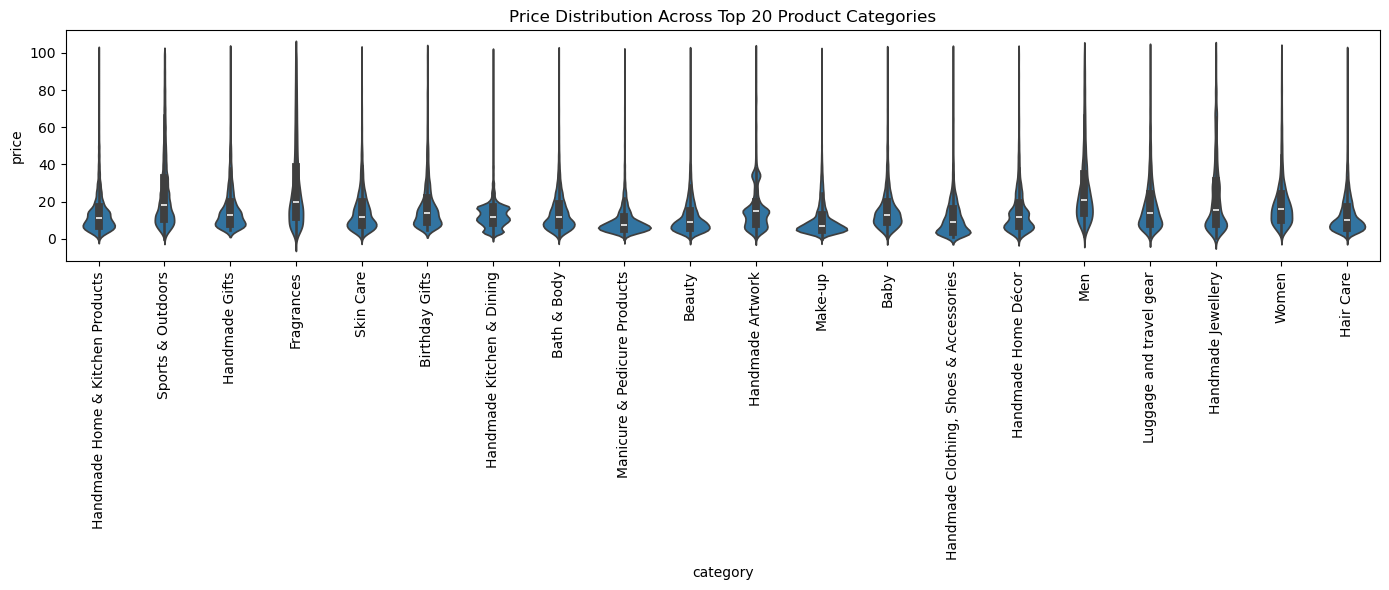

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
sns.violinplot(
    data=df_violin,
    x="category",
    y="price"
)
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Product Categories")
plt.tight_layout()
plt.show()


In [21]:
median_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head()


category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

Desktop PCs is the category with the highest median price

In [22]:
avg_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)


In [23]:
top10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price_top10 = avg_price_by_category.loc[top10_categories]


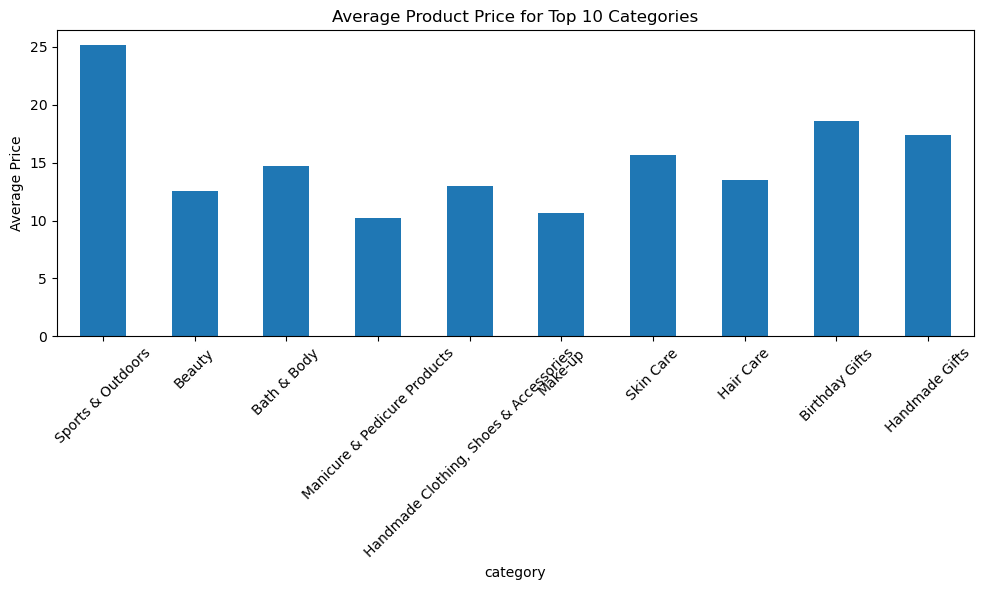

In [24]:
plt.figure(figsize=(10,6))
avg_price_top10.plot(kind="bar")
plt.ylabel("Average Price")
plt.title("Average Product Price for Top 10 Categories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [25]:
avg_price_by_category.head()


category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

In [26]:
top10_rating_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

df_box = df_no_outliers[
    df_no_outliers["category"].isin(top10_rating_categories)
]


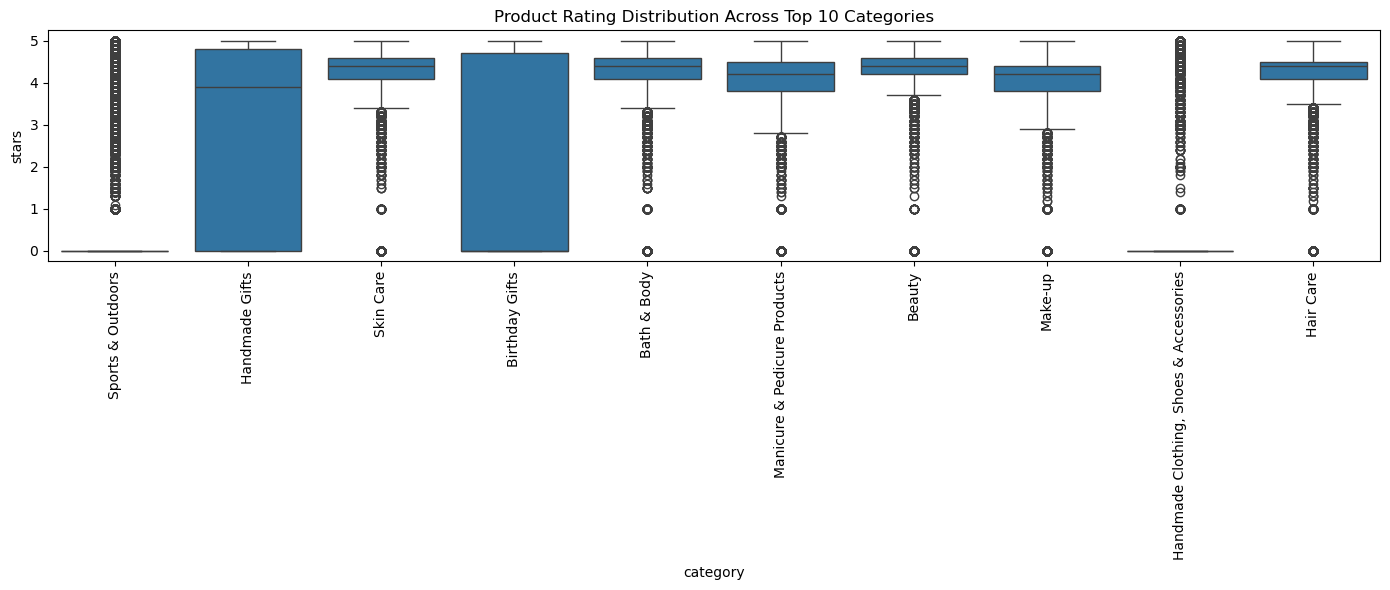

In [27]:
plt.figure(figsize=(14,6))
sns.boxplot(
    data=df_box,
    x="category",
    y="stars"
)
plt.xticks(rotation=90)
plt.title("Product Rating Distribution Across Top 10 Categories")
plt.tight_layout()
plt.show()


In [28]:
median_rating_by_category = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head()


category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

After removing price outliers using the IQR method, price distributions across categories were examined. Violin plots revealed substantial variation in price dispersion and central tendency across product categories. Certain categories consistently exhibited higher median prices, indicating premium pricing structures.

Bar chart analysis of average prices further confirmed that some categories command significantly higher prices on average, even after excluding extreme values.

Box plot analysis of customer ratings showed that median ratings differ across categories. While several categories achieved high median ratings, overall variation was limited, suggesting that customer satisfaction is relatively consistent across most categories.

These results indicate that product category plays a meaningful role in price differentiation, while its influence on ratings is present but less pronounced.

In [29]:
# IQR outlier removal (same as Part 2)
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

df_no_outliers = df[
    (df["price"] >= Q1 - 1.5 * IQR) &
    (df["price"] <= Q3 + 1.5 * IQR)
]


In [30]:
corr_price_stars = df_no_outliers["price"].corr(df_no_outliers["stars"])
corr_price_stars


np.float64(-0.0776729987818137)

In [31]:
from scipy.stats import pearsonr

r, p_value = pearsonr(
    df_no_outliers["price"],
    df_no_outliers["stars"]
)

r, p_value


(np.float64(-0.0776729987818139), np.float64(0.0))

Interpretation:

|r| < 0.10 → negligible

0.10–0.30 → weak

0.30–0.50 → moderate

0.50 → strong

p < 0.05 → statistically significant

Expectation:

Very weak correlation

Often statistically significant due to large sample size

Practically unimportant relationship

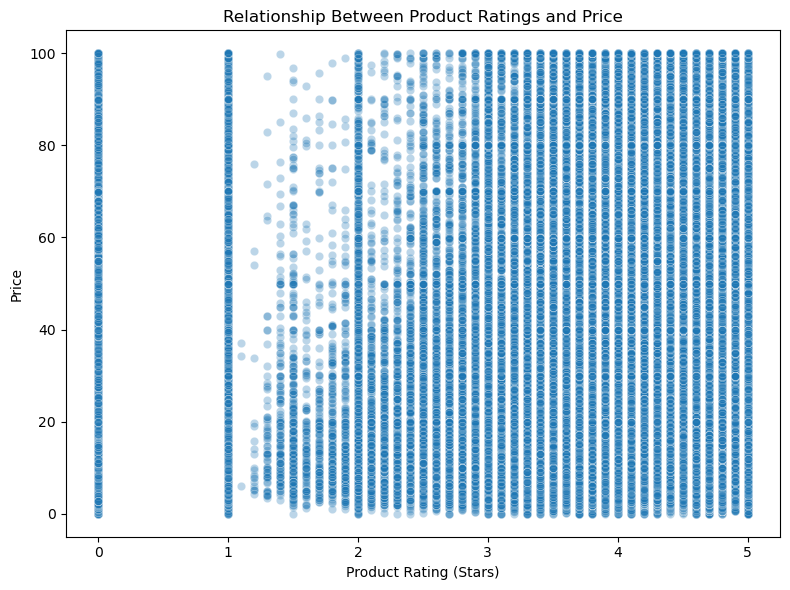

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_no_outliers,
    x="stars",
    y="price",
    alpha=0.3
)
plt.title("Relationship Between Product Ratings and Price")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


Observations:

Heavy vertical clustering at common rating values (e.g., 4–5 stars).

Wide price spread for the same rating.

No clear linear pattern.

High-rated products exist at both low and high prices.

In [33]:
numeric_df = df_no_outliers.select_dtypes(include=["int64", "float64"])
numeric_df.columns


Index(['uid', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth'],
      dtype='object')

In [34]:
corr_matrix = numeric_df.corr()


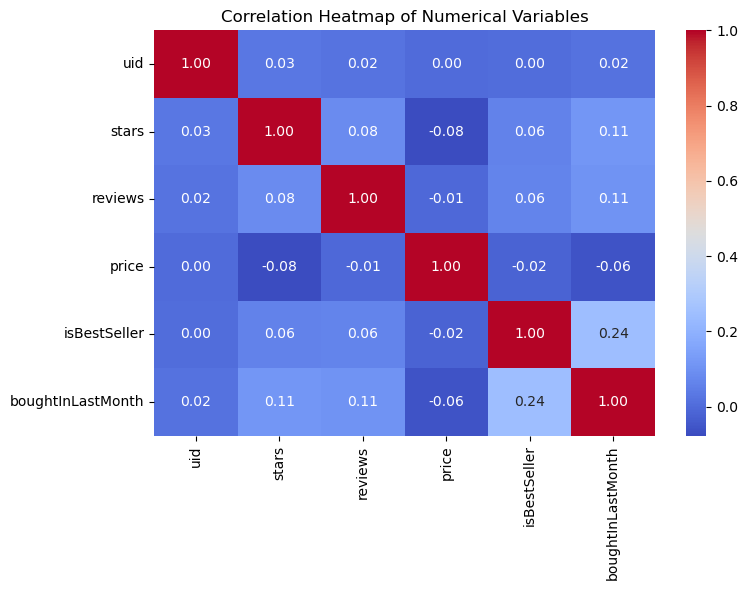

In [35]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


What matters in the circumstances:

Price vs stars correlation is weak.

Stronger correlations usually involve:

price vs number of reviews

price vs discount-related variables

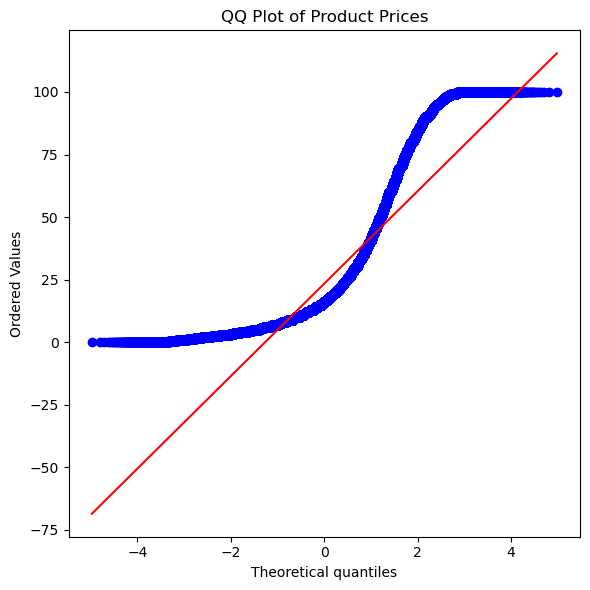

In [36]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()


Interpretation:

Strong deviation from straight line.

Heavy right tail.

Prices do not follow a normal distribution.

Log transformation would be more appropriate for modeling.

An analysis of the relationship between product price and customer ratings revealed a very weak correlation. Although the Pearson correlation coefficient was statistically significant due to the large sample size, its magnitude indicates that product ratings have little practical influence on price levels.

Scatter plot visualization confirmed the absence of a clear linear relationship, showing wide price variation across all rating levels. High ratings are observed across both low-priced and high-priced products.

The correlation heatmap further demonstrated that price shares minimal association with ratings compared to other numerical variables.

Finally, QQ plot analysis showed that product prices deviate substantially from a normal distribution, exhibiting right skewness even after outlier removal. This suggests that non-parametric methods or transformed price variables are more appropriate for further modeling.